<a href="https://colab.research.google.com/github/JoelvdR/medicalAI/blob/main/Group15_%5BMAM11A_2026%5D_V%26L_Practicum_Uncertainty_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Practicum Vision & Language NLP - Uncertainty Quantification with Multimodal LLMs

In this notebook, we will evaluate several multimodal Vision & Language LLMs on a Medical Visual Question Answering task. We will use the following dataset: [GMAI-MMBench: A Comprehensive Multimodal Evaluation Benchmark Towards General Medical AI.](https://huggingface.co/datasets/OpenGVLab/GMAI-MMBench) The dataset is released under the Apache 2.0 license, and you will work on a pre-processed subset prepared by us.

We will evaluate several models:
- `Qwen2-VL-2B-Instruct` and `Medgemma-4b-it` (smaller models that can be run directly on Colab; output files are also provided in case of issues).
- `Qwen2.5-VL-32B-Instruct` and `GPT-5-mini` (larger models - we provide the output files).

Output files are named according to the following template:
`outputs_{model_name}-sample_{sample_answers}-temp_{temperature}.tsv`

### Setup

- In Runtime, select Change runtime type, then choose **T4 GPU** as the hardware accelerator.  

- Log into Hugging Face and accept the license agreement for [Qwen2-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct) and [Medgemma-4b-it](https://huggingface.co/google/medgemma-4b-it). Attention, this may take a while to be processed.

- Set your Hugging Face token as the variable **HF_TOKEN** in the Secrets tab (left menu, key icon) or paste your token in the "your_token" in the required field. Make sure not to accidentaly share it.


### Important Note

This challenging assignment gives you plenty of freedom to explore and be creative. You are expected to demonstrate independence, formulate your own hypotheses, and test them empirically. Since this is a cutting-edge research area with many open questions, take the opportunity to investigate, experiment, and follow your curiosity! :)


####Students: Name:
Emmanuella Ekpenyong - UvA id:16411773  
Name: Britt  Uiterdijk -	UvA id:13451308  
Name: Joël van der Roest- UvA id:14371839

In [ ]:
from typing import List, Dict, Any, Tuple, Generator, Optional, Union
import random
import string, os, sys, glob
import pandas as pd
import numpy as np
from google.colab import userdata

from PIL import Image
from tqdm import tqdm
import torch
import ast

In [ ]:
try:
  hf_token = userdata.get('HF_TOKEN')
except userdata.SecretNotFoundError:
  hf_token = "your_token"

os.environ["HF_TOKEN"] = hf_token

In [ ]:
!gdown --folder https://drive.google.com/drive/folders/1dNoFV9GvDhMdTjM2P2oHW00-f9oPMxnf -O /content/data # download pre-processed dataset files + model responses
!unzip -q data/filtered_images.zip -d data/images/ # unzip the images folder

Retrieving folder contents
Retrieving folder 1MxSEpKZWI26Gl2dVdvRd2uMn7Eimr9dC model_responses
Processing file 1tG8zYy11gXQ-puRQocji6OOKogHR12Pi outputs_gpt5-mini_no-logprobs.tsv
Processing file 1GVFn2qKdDJxtEbbrufC0W7eULvAZMyPa outputs_medgemma-4b-it-temp_0.2.tsv
Processing file 1BAx2jUeuUbgRX6joWR94vdS0nsqCNf-I outputs_medgemma-4b-it-temp_0.6.tsv
Processing file 1JK7ACAkPVKIyEZ39RtVru3GDgUvMk_8J outputs_medgemma-4b-it-temp_1.0.tsv
Processing file 18cSUZl93yG167twxUY_gmEaMYXDOfi3q outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
Processing file 1pxUlsk9rK67Uo9mOSxKKOebMzGxPYXS9 outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
Processing file 1WlgSroLtv5STSufSC4qRM419KW5YRBod outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
Processing file 1HjbP_JjNq1gkqsz-RiXff-c5M_tvPvb8 outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
Processing file 11XjxhRI7j-xOEtnTYnE7-v8pFTOk6jIh outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
Processing file 1FSfXTQj2ytMsCfO0Iy_xoeP0P-IqI-K7 outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv
Pr

# 1. Inference (run on GPUs)

## Load and Prepare Model Inputs

In [ ]:
def add_options_dict(df_raw: pd.DataFrame) -> pd.DataFrame:  # prepare the multiple-choice question format
    option_cols = [col for col in df_raw.columns if col in list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")]

    def _make_dict(row):
        return {col: row[col] for col in option_cols if pd.notna(row[col])}

    out = df_raw.copy()
    out["options"] = out.apply(_make_dict, axis=1)
    return out

def construct_prompt(row) -> str:  # prepare the prompt for the model
    PROMPT_TEMPLATE = """Question: ({question})
Provide a concise answer and start your response with the letter of the selected option in square brackets. Options:
(
{options}
)
Your Answer:
"""
    question = row["question"]
    options = {
        letter: row[letter]
        for letter in string.ascii_uppercase[:5]
        if letter in row and row[letter] and str(row[letter]).strip() and not pd.isna(row[letter])
    }

    formatted_options = "\n".join(
        f"[{letter}] {option}"
        for letter, option in options.items()
    )

    return PROMPT_TEMPLATE.format(
        question=question,
        options=formatted_options
    )

In [ ]:
input_tsv = "data/GMAI_mm_bench_dataset.tsv"  # the pre-processed dataset we provide
df = pd.read_csv(input_tsv, sep="\t")

df = add_options_dict(df)
df["prompt"] = df.apply(lambda row: construct_prompt(row), axis=1)
data_records: List[dict] = df.to_dict(orient="records")

In [ ]:
df.head()  # inspect the data

,index,question,A,B,C,D,E,answer,category,clinical VQA task,department,perceptual granularity,modality,original task,image_path,options,prompt
0,398,Which of the following options best matches th...,fascia uncovered kidney parenchyma,lung,fascia covered kidney parenchyma,heart,clavicles,D,heart,Organ Recognition - Thorax,Cardiovascular Surgery,Contour level,X-ray,SEG_2D,398.jpg,"{'A': 'fascia uncovered kidney parenchyma', 'B...",Question: (Which of the following options best...
1,4322,"Observe the image, please select the option th...",grade 2 (minimal),grade 3 (moderate),grade 4 (severe),grade 1 (doubtful),NaN,A,grade 2 (minimal),Severity Grading,Sports Medicine,Image level,X-ray,CLS_2D,4322.jpg,"{'A': 'grade 2 (minimal)', 'B': 'grade 3 (mode...","Question: (Observe the image, please select th..."
2,2627,Considering the symptoms visible in the pictur...,COVID 19,viral pneumonia,normal chest x ray,NaN,NaN,B,viral pneumonia,Disease Diagnosis,Pulmonary Medicine,Image level,X-ray,CLS_2D,2627.jpg,"{'A': 'COVID 19', 'B': 'viral pneumonia', 'C':...",Question: (Considering the symptoms visible in...
3,70,Focus on the square-highlighted area of this X...,pulmonary mass,diffuse pulmonary nodule,pleural effusion,pulmonary calcification,NaN,A,pulmonary mass,Disease Diagnosis,Pulmonary Medicine,Box level,X-ray,DET_2D,70.jpg,"{'A': 'pulmonary mass', 'B': 'diffuse pulmonar...",Question: (Focus on the square-highlighted are...
4,4525,Choose the description that best matches the i...,negative for pneumonia,typical appearance of COVID-19,indeterminate appearance of COVID-19,atypical appearance of COVID-19,NaN,C,indeterminate appearance of COVID-19,Severity Grading,Pulmonary Medicine,Image level,X-ray,CLS_2D,4525.jpg,"{'A': 'negative for pneumonia', 'B': 'typical ...",Question: (Choose the description that best ma...


In [ ]:
len(df) # we have 300 image-question pairs

300

In [ ]:
# Q1
for column in ["clinical VQA task", "department"]:
    counts = df[column].fillna("Missing").value_counts()
    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage": (counts / len(df) * 100).round(1)
    })
    print(f"\n{column}")
    print(distribution.to_string())


clinical VQA task
                                   Count  Percentage
clinical VQA task                                   
Disease Diagnosis                    182        60.7
Organ Recognition - Thorax            25         8.3
Bone                                  22         7.3
Severity Grading                      16         5.3
Organ Recognition - Abdomen           14         4.7
Organ Recognition - Head and Neck     13         4.3
Blood Vessels Recognition             10         3.3
Muscle                                 7         2.3
Organ Recognition - Pelvic             7         2.3
Attribute Recognition                  4         1.3

department
                                            Count  Percentage
department                                                   
Pulmonary Medicine                             76        25.3
Sports Medicine                                50        16.7
Orthopedic Surgery                             49        16.3
Gastroenterology and He

## a. Inference with Qwen2-VL-2B-Instruct

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image

model_id = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
)

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
).eval()

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [ ]:
model.device # verify this is running on 'cuda'

device(type='cuda', index=0)

In [ ]:
images_dir = "data/images"

def format_inputs(batch_item: Dict[str, Any]) -> Dict[str, Any]:
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image"},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": Image.open(os.path.join(images_dir, batch_item["image_path"]))
    }

In [ ]:
batch_size = 4
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10  # we sample 10 responses for each question.

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        images=images_batch,
        text=prompts_batch,
        return_tensors="pt",
        padding=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(**inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.logits):  # extract the probability associated to each generated token
            if j >= generated_tokens.shape[0]:  # Avoid out-of-bounds if gen shorter than scores
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path':item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

  0%|          | 2/750 [00:09<57:35,  4.62s/it]


KeyboardInterrupt: 

In [ ]:
# Q2
from pathlib import Path
import ast

# Load files from the folder
folder = Path("/content/data/model_responses")
files = sorted(folder.glob("*.tsv"))

results = pd.concat(
    [pd.read_csv(file, sep="\t") for file in files],
    ignore_index=True
)


# Count each question only once
analysis_df = results.drop_duplicates(subset="index").copy()
n = len(analysis_df)

if n == 0:
    raise ValueError("The files contain no questions.")

print(f"Unique questions: {n}")

# Average question length in words
questions = analysis_df["question"].fillna("").astype(str).str.strip()
word_counts = questions.str.split().str.len()
print(f"\nAverage question length: {word_counts.mean():.2f} words")

# Questions ending with a question mark
ends_with_question_mark = questions.str.endswith("?")
print(
    f"Questions ending with '?': {ends_with_question_mark.sum()} "
    f"({ends_with_question_mark.mean():.1%})"
)


# Number of available answer options per question
def count_options(options):
    if isinstance(options, str):
        options = ast.literal_eval(options)

    if isinstance(options, dict):
        values = list(options.values())
    elif isinstance(options, (list, tuple)):
        values = list(options)

    return sum(
        value is not None
        and pd.notna(value)
        and str(value).strip() != ""
        for value in values
    )

option_counts = analysis_df["options"].apply(count_options)

if option_counts.eq(0).any():
    raise ValueError("Some questions have no available answer options.")

print("\nDistribution of the number of answer options:")
for number, count in option_counts.value_counts().sort_index().items():
    print(f"{number} options: {count} questions ({count / n:.1%})")


# Distribution of gold answer letters.
gold = (
    analysis_df["gold_label"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

letters = ["A", "B", "C", "D", "E"]
gold_counts = gold.value_counts().reindex(letters, fill_value=0)

print("\nDistribution of gold answer letters:")
for letter, count in gold_counts.items():
    print(f"{letter}: {count} questions ({count / n:.1%})")


# Expected accuracy when choosing uniformly among available options
random_accuracy = (1 / option_counts).mean()

# Accuracy when always choosing the most frequent gold letter
most_frequent_letter = gold_counts.idxmax()
majority_accuracy = gold.eq(most_frequent_letter).mean()

print("\nBaselines:")
print(f"Expected uniform random accuracy: {random_accuracy:.2%}")
print(f"Majority-letter accuracy: {majority_accuracy:.2%}")

Unique questions: 300

Average question length: 14.32 words
Questions ending with '?': 274 (91.3%)

Distribution of the number of answer options:
2 options: 7 questions (2.3%)
3 options: 1 questions (0.3%)
4 options: 210 questions (70.0%)
5 options: 82 questions (27.3%)

Distribution of gold answer letters:
A: 67 questions (22.3%)
B: 75 questions (25.0%)
C: 70 questions (23.3%)
D: 69 questions (23.0%)
E: 19 questions (6.3%)

Baselines:
Expected uniform random accuracy: 24.24%
Majority-letter accuracy: 25.00%


In [ ]:
# Q3
# Load files from the folder
folder = Path("/content/data/model_responses")
files = sorted(folder.glob("*.tsv"))

results = pd.concat(
    [pd.read_csv(file, sep="\t") for file in files],
    ignore_index=True
)

# Select an actual dataset question.
example = results.drop_duplicates(subset="index").iloc[0]

print("Question:")
print(example["question"])

print("\nAnswer options:")
print(example["options"])

print("\nGold answer:")
print(example["gold_label"])

Question:
Which of the following options best matches the marked organ in the X-ray image?

Answer options:
{'A': 'fascia uncovered kidney parenchyma', 'B': 'lung', 'C': 'fascia covered kidney parenchyma', 'D': 'heart', 'E': 'clavicles'}

Gold answer:
D


In [ ]:
#Q4
import pandas as pd
import numpy as np
import ast

# Load responses and parse columns directly
df_raw = pd.read_csv("./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv", sep="\t")
df_raw["options"] = df_raw["options"].apply(ast.literal_eval)
df_raw["parsed_logprobs"] = df_raw["logprobs"].apply(ast.literal_eval)

# Inspect the requested example at index 454
row = df_raw[df_raw["index"] == 454].iloc[0]

print("Question:", row["question"])
print("Options :", row["options"])
print("Gold    :", row["gold_label"])
print("Response (decode output):", repr(row["response"]))
print("\nParsed Logprobs:")
print(f"{'Token':<22}{'Logprob':<10}{'Probability':<12}")
print("-"*44)
for tok, lp in row["parsed_logprobs"]:
    print(f"{tok!r:22}{lp:10.4f}{np.exp(lp):12.6f}")

Question: Which of the following options best matches the marked organ in the X-ray image?
Options : {'A': 'stomach', 'B': 'small intestine', 'C': 'optic cup', 'D': 'kidney boundary', 'E': 'clavicles'}
Gold    : E
Response (decode output): '[D] kidney boundary'

Parsed Logprobs:
Token                 Logprob   Probability 
--------------------------------------------
'[D'                     -0.0345    0.966074
']'                      -0.0033    0.996749
' kidney'                -0.0090    0.991046
' boundary'              -0.0006    0.999385
'<|im_end|>'             -0.0009    0.999118
'<|endoftext|>'         -18.3125    0.000000
'<|endoftext|>'         -13.0555    0.000002
'<|endoftext|>'         -13.1087    0.000002
'<|endoftext|>'          -9.8509    0.000053


## b. Inference with medgemma-4b-it

In [ ]:
import gc

# Release the previous model and tensors from its inference loop.
for name in (
    "model", "processor", "inputs", "outputs", "input_ids",
    "generated_tokens", "logits", "probs"
):
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image
import requests

model_id = "google/medgemma-4b-it"

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(model_id)

config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

In [ ]:
model.device

device(type='cuda', index=0)

In [ ]:
images_dir = "data/images"

def format_inputs(batch_item: Dict[str, Any]) -> Dict[str, Any]:
    image = Image.open(os.path.join(images_dir, batch_item["image_path"]))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image", "image":image},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": [image],
    }

In [ ]:
batch_size = 1
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        text=prompts_batch,
        images=images_batch,
        padding=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.bfloat16)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.scores):
            if j >= generated_tokens.shape[0]:
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path': item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

  0%|          | 3/3000 [00:16<4:34:47,  5.50s/it]


KeyboardInterrupt: 

## Compute and Save Embeddings of Model Outputs
In Section 2, you will compute and evaluate several Uncertainty Estimation (UE) methods. One of these is Radial Dispersion Score (RDS), an embedding-based UE method. To prepare for this, we first need to compute and save the embeddings of all model responses.
We will:

1. Compute and save the embeddings for all model responses.
2. Zip the folder containing the embeddings.
3. Download the zip file.
4. Change the runtime to CPU (see Section 2) and upload the zip file to the runtime.

In [ ]:
# Load the embedding model
from sentence_transformers import SentenceTransformer
import numpy as np
import os

embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
os.makedirs("/content/data/embeddings", exist_ok=True)
embeddings_folder = "/content/data/embeddings"
outputs_folder = "/content/data/model_responses/"

def embed_save_outputs(df, output_path, embedding_model):
    sentences = df["response"].tolist()
    sentences = [str(s) for s in sentences]
    embeddings = embedding_model.encode(sentences, batch_size=32, show_progress_bar=True)
    np.save(output_path, embeddings)

for path in glob.glob(os.path.join(outputs_folder, "*")):
    filename = os.path.basename(path)
    filename = filename.replace("outputs_", "").replace(".tsv", "")
    embedding_file = os.path.join(embeddings_folder, f"embeddings_{filename}.npy")
    df = pd.read_csv(path, sep='\t')
    if not os.path.exists(embedding_file):
        embed_save_outputs(df, embedding_file, embedding_model)

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/65 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

In [ ]:
# We will zip the /content/data/embeddings folder, download the zip file manually, since restarting the runtime will delete the results.
! zip -r /content/data/embeddings.zip /content/data/embeddings

  adding: content/data/embeddings/ (stored 0%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_1.0.npy (deflated 73%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_0.6.npy (deflated 86%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_0.6.npy (deflated 80%)
  adding: content/data/embeddings/embeddings_gpt5-mini_no-logprobs.npy (deflated 39%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_1.0.npy (deflated 84%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_1.0.npy (deflated 23%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_0.2.npy (deflated 33%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_0.2.npy (deflated 88%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_0.2.npy (deflated 87%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_0.6.npy (deflated 22%)


# 2. Load and Analyze Outputs (run on CPUs) - Uncertainty Quantification


In [ ]:
import re
from collections import Counter
import ast
import numpy as np
import pandas as pd

### a. Utilities and Implementations for
* Answer extraction, accuracy, majority voting
* Uncertainty Estimation (UE) methods:
  * **Token-level probability** (log-likelihood): the probability assigned to each generated token in a response, used as a proxy for model uncertainty. Higher probability = higher confidence. Note: this is not available for `GPT-5-mini`. You have to implement this method (see the assignment report).
  * **Semantic Entropy**: measures the consistency of multiple responses to the same question. More consistent responses across runs = higher model confidence.
  * **Radial Dispersion Score (RDS)**: measures the dispersion of embeddings from their centroid, for multiple responses to the same question. You have to implement this method (see the assignment report). Note: Don't forget to upload the zip file with the saved embeddings, and unzip it!
* Uncertainty Estimation evaluation metrics:
  * Discrimination metric: Area Under the Receiver Operating Characteristic Curve (**AUROC**)
  * Calibration metrics: Expected Calibration Error (**ECE**) and **Brier Score**.


In [ ]:
def parse_response(response):
    """Extract the letter choice from the response."""
    # Look for pattern like [A], [B], etc.
    match = re.search(r'\[([A-E])\]', response)
    if match:
        return match.group(1)
    return None

def parse_options(options_str):
    """Parse the options string to get the number of options."""
    try:
        # Convert string representation of dict to actual dict
        options_dict = ast.literal_eval(options_str)
        return len(options_dict)
    except:
        # Fallback: assume 5 options if parsing fails
        return 5

def load_and_process_data(file_path):
    """Load the TSV file and process the data."""
    df = pd.read_csv(file_path, sep='\t')

    # Parse responses to extract letter choices
    df['parsed_response'] = df['response'].apply(parse_response)

    # Parse options to get number of choices per question
    df['num_options'] = df['options'].apply(parse_options)

    return df

def compute_accuracy_stats(df):
    """Compute overall accuracy and per-question statistics."""
    stats = {}

    # Overall accuracy
    correct_predictions = (df['parsed_response'] == df['gold_label']).sum()
    total_predictions = len(df)
    overall_accuracy = correct_predictions / total_predictions

    stats['overall_accuracy'] = overall_accuracy
    stats['total_samples'] = total_predictions
    stats['correct_predictions'] = correct_predictions

    # Per-question statistics (grouped by index, which is unique per question)
    question_stats = []
    unique_indices = df['index'].unique()

    for idx in unique_indices:
        question_data = df[df['index'] == idx]

        # Get all responses for this question (should be 10 samples)
        responses = question_data['parsed_response'].tolist()
        gold_label = question_data['gold_label'].iloc[0]  # Should be same for all samples
        question_text = question_data['question'].iloc[0]  # Should be same for all samples
        num_options = question_data['num_options'].iloc[0]  # Should be same for all samples

        # Calculate accuracy for this question
        correct = sum(1 for r in responses if r == gold_label)
        accuracy = correct / len(responses)

        # Calculate consistency (how often the model gives the same answer)
        response_counts = Counter(responses)
        most_common_response, most_common_count = response_counts.most_common(1)[0]
        consistency = most_common_count / len(responses)

        # Calculate entropy of responses (lower = more consistent)
        response_probs = np.array(list(response_counts.values())) / len(responses)
        entropy = -np.sum(response_probs * np.log2(response_probs))

        question_stats.append({
            'index': idx,
            'question': question_text[:50] + '...' if len(question_text) > 50 else question_text,
            'gold_label': gold_label,
            'accuracy': accuracy,
            'consistency': consistency,
            'most_common_response': most_common_response,
            'entropy': entropy,
            'num_samples': len(responses),
            'num_options': num_options
        })

    stats['question_stats'] = question_stats
    return stats


In [ ]:
def compute_semantic_entropy_uncertainty(df):
    """
    Compute semantic entropy as uncertainty metric and evaluate it.
    For each question, semantic entropy measures how uncertain the model is.
    """
    grouped = df.groupby('index')

    uncertainties = []
    correctness = []  # Binary: 1 if majority answer is correct, 0 otherwise
    num_options_list = []  # Track number of options for each question

    for idx, group in grouped:
        responses = group['parsed_response'].tolist()
        gold_label = group['gold_label'].iloc[0]
        num_options = group['num_options'].iloc[0]

        # Count responses
        response_counts = Counter(responses)
        total_responses = len(responses)

        # Calculate semantic entropy (uncertainty)
        response_probs = np.array(list(response_counts.values())) / total_responses
        semantic_entropy = -np.sum(response_probs * np.log2(response_probs))

        # Determine if majority answer is correct
        most_common_response = response_counts.most_common(1)[0][0]
        is_correct = 1 if most_common_response == gold_label else 0

        uncertainties.append(semantic_entropy)
        correctness.append(is_correct)
        num_options_list.append(num_options)

    return np.array(uncertainties), np.array(correctness), np.array(num_options_list)


def compute_calibration_metrics(uncertainties, correctness, n_bins=10):
    """Compute AUROC, ECE, and Brier score with dynamic normalization."""

    from sklearn.metrics import roc_auc_score

    # AUROC: How well does uncertainty predict incorrectness?
    # Higher uncertainty should predict lower correctness
    try:
        auroc = roc_auc_score(1 - correctness,
                              uncertainties)  # 1-correctness because higher uncertainty should predict incorrectness
    except ValueError:
        auroc = 0.5  # If all samples have same correctness

    # Expected Calibration Error (ECE)
    def compute_ece(uncertainties, correctness, n_bins=10):
        bin_edges = np.linspace(0, np.max(uncertainties) + 1e-8, n_bins + 1)
        ece = 0

        for i in range(n_bins):
            mask = (uncertainties >= bin_edges[i]) & (uncertainties < bin_edges[i + 1])
            if np.sum(mask) > 0:
                bin_accuracy = np.mean(correctness[mask])
                bin_confidence = 1 - np.mean(uncertainties[mask])
                bin_confidence = np.clip(bin_confidence, 0, 1)  # Ensure it's between 0 and 1
                bin_size = np.sum(mask) / len(uncertainties)
                ece += bin_size * abs(bin_accuracy - bin_confidence)

        return ece

    u_min, u_max = uncertainties.min(), uncertainties.max()
    if u_max > u_min:
        uncertainties = (uncertainties - u_min) / (u_max - u_min)
    else:
        uncertainties = np.zeros_like(uncertainties)
    confidences = 1 - uncertainties
    confidences = np.clip(confidences, 0, 1)

    ece = compute_ece(uncertainties, correctness, n_bins)
    brier_score = np.mean((confidences - correctness) ** 2)

    return auroc, ece, brier_score

### b. Run Evaluation

In [ ]:
# Replace this with the output file corresponding to the model and decoding configuration you want to evaluate.
file_path = "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv"

print("Loading and processing data...")
df = load_and_process_data(file_path)

print(f"Loaded {len(df)} samples")
print(f"Number of unique questions (indices): {df['index'].nunique()}")
print(f"Samples per question: {len(df) // df['index'].nunique()}")

# Print option distribution
option_counts = df.groupby('index')['num_options'].first().value_counts().sort_index()
print(f"Distribution of number of options:")
for num_opts, count in option_counts.items():
    print(f"  {num_opts} options: {count} questions")

Loading and processing data...
Loaded 3000 samples
Number of unique questions (indices): 300
Samples per question: 10
Distribution of number of options:
  2 options: 7 questions
  3 options: 1 questions
  4 options: 210 questions
  5 options: 82 questions


In [ ]:
# Basic accuracy statistics
print("\n" + "=" * 50)
print("ACCURACY ANALYSIS")
print("=" * 50)

stats = compute_accuracy_stats(df)
print(f"Overall Accuracy: {stats['overall_accuracy']:.3f}")
print(f"Correct Predictions: {stats['correct_predictions']}/{stats['total_samples']}")

# Per-question statistics
print(f"\nPer-Question Statistics:")
print("-" * 100)
print(f"{'Index':<6} {'Question':<50} {'Gold':<5} {'Opts':<7} {'Acc':<6} {'Cons':<2} {'Pred':<4} {'Entropy':<7}")
print("-" * 100)
for q_stat in stats['question_stats']:
    print(f"{q_stat['index']:<6} {q_stat['question']:<40} {q_stat['gold_label']:<4} "
          f"{q_stat['num_options']:<4} {q_stat['accuracy']:<6.3f} {q_stat['consistency']:<6.3f} "
          f"{q_stat['most_common_response']:<4} {q_stat['entropy']:<7.3f}")


ACCURACY ANALYSIS
Overall Accuracy: 0.316
Correct Predictions: 948/3000

Per-Question Statistics:
----------------------------------------------------------------------------------------------------
Index  Question                                           Gold  Opts    Acc    Cons Pred Entropy
----------------------------------------------------------------------------------------------------
398    Which of the following options best matches the ma... D    5    0.100  0.600  B    1.295  
4322   Observe the image, please select the option that b... A    4    0.000  0.900  C    0.469  
2627   Considering the symptoms visible in the picture, w... B    3    0.800  0.800  B    0.722  
70     Focus on the square-highlighted area of this X-ray... A    4    0.200  0.700  B    1.157  
4525   Choose the description that best matches the image... C    4    0.000  0.600  D    0.971  
2277   Which of the following options best matches the co... C    4    0.000  0.500  D    1.361  
57     Observe

In [ ]:
# Uncertainty quantification analysis
print("\n" + "=" * 60)
print("UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy")
print("=" * 60)

uncertainties, correctness, num_options_array = compute_semantic_entropy_uncertainty(df)
auroc, ece, brier_score = compute_calibration_metrics(uncertainties, correctness)

print(f"\n Discrimination and Calibration Metrics:\n")
print(f" * AUROC (uncertainty vs incorrectness): {auroc:.3f}")
print(f" * Expected Calibration Error (ECE): {ece:.3f}")
print(f" * Brier Score: {brier_score:.3f}")


UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy

 Discrimination and Calibration Metrics:

 * AUROC (uncertainty vs incorrectness): 0.595
 * Expected Calibration Error (ECE): 0.159
 * Brier Score: 0.256


In [ ]:
# Q5
example = df[df["index"] == 767]

print("Example question:")
print(example["question"].iloc[0])
print("Number of responses:", len(example))
print("\nAnswer counts:")
print(example["parsed_response"].value_counts(dropna=False))

counts = example["parsed_response"].value_counts(dropna=False)
probs = counts.to_numpy() / counts.sum()

manual_entropy = -np.sum(probs * np.log2(probs))

print("\nManual entropy:", round(manual_entropy, 3))


Example question:
This is a X-ray image. Which of the following options is the most appropriate to demonstrate the marked area?
Number of responses: 10

Answer counts:
parsed_response
E    5
B    3
A    1
C    1
Name: count, dtype: int64

Manual entropy: 1.685


In [ ]:
# Q6
example = df[df['index'] == 755]

print("Question:", example['question'].iloc[0])
print("Options:", example['options'].iloc[0])
print("Gold answer:", example['gold_label'].iloc[0])
print("\nSampled responses:\n")

for i, (_, row) in enumerate(example.iterrows(), start=1):
    print(f"Sample {i}:")
    print("Full response:", row['response'])
    print("Extracted answer:", row['parsed_response'])
    print("-" * 50)

Question: Which of the following options best matches the symptoms of marked region shown in the X-ray image?
Options: {'A': 'cardiomegaly', 'B': 'lung nodule', 'C': 'pneumothorax', 'D': 'lung calcification', 'E': 'atelectasis'}
Gold answer: E

Sampled responses:

Sample 1:
Full response: [D]
Extracted answer: D
--------------------------------------------------
Sample 2:
Full response: [B] lung nodule
Extracted answer: B
--------------------------------------------------
Sample 3:
Full response: [A] cardiomegaly
Extracted answer: A
--------------------------------------------------
Sample 4:
Full response: [B]
Extracted answer: B
--------------------------------------------------
Sample 5:
Full response: [D] lung calcification
Extracted answer: D
--------------------------------------------------
Sample 6:
Full response: [C] pneumothorax
Extracted answer: C
--------------------------------------------------
Sample 7:
Full response: [B]
Extracted answer: B
-----------------------------

In [ ]:
# Q7
files = sorted(glob.glob("./data/model_responses/*.tsv"))

results = []

for file_path in files:
    # Load the saved responses
    df_config = load_and_process_data(file_path)

    # Calculate entropy and correctness
    uncertainties, correctness, _ = compute_semantic_entropy_uncertainty(df_config)

    # Calculate evaluation metrics
    auroc, ece, brier = compute_calibration_metrics(
        uncertainties, correctness
    )

    results.append({
        "Configuration": file_path.split("/")[-1].replace("outputs_", "").replace(".tsv", ""),
        "AUROC": auroc,
        "ECE": ece,
        "Brier Score": brier
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))
print("Best AUROC (highest):")
display(results_df.loc[[results_df["AUROC"].idxmax()]].round(3))

print("\nBest ECE (lowest):")
display(results_df.loc[[results_df["ECE"].idxmin()]].round(3))

print("\nBest Brier Score (lowest):")
display(results_df.loc[[results_df["Brier Score"].idxmin()]].round(3))

,Configuration,AUROC,ECE,Brier Score
0,Qwen2-VL-2B-Instruct-temp_0.2,0.530,0.539,0.544
1,Qwen2-VL-2B-Instruct-temp_0.6,0.578,0.322,0.362
2,Qwen2-VL-2B-Instruct-temp_1.0,0.595,0.159,0.256
3,Qwen2.5-VL-32B-Instruct-temp_0.2,0.549,0.419,0.425
4,Qwen2.5-VL-32B-Instruct-temp_0.6,0.608,0.293,0.352
5,Qwen2.5-VL-32B-Instruct-temp_1.0,0.670,0.211,0.278
6,gpt5-mini_no-logprobs,0.638,0.226,0.238
7,medgemma-4b-it-temp_0.2,0.518,0.587,0.585
8,medgemma-4b-it-temp_0.6,0.532,0.540,0.545
9,medgemma-4b-it-temp_1.0,0.552,0.519,0.521


Best AUROC (highest):


,Configuration,AUROC,ECE,Brier Score
5,Qwen2.5-VL-32B-Instruct-temp_1.0,0.67,0.211,0.278



Best ECE (lowest):


,Configuration,AUROC,ECE,Brier Score
2,Qwen2-VL-2B-Instruct-temp_1.0,0.595,0.159,0.256



Best Brier Score (lowest):


,Configuration,AUROC,ECE,Brier Score
6,gpt5-mini_no-logprobs,0.638,0.226,0.238


In [ ]:
#Q8
import pandas as pd
import re
from collections import Counter

files = {
    "0.2": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv",
    "0.6": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "1.0": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
}

for temp, path in files.items():
    df = pd.read_csv(path, sep="\t")

    # Extract answer letters A-E; invalid responses become None
    df["answer"] = df["response"].apply(
        lambda x: re.search(r"\[([A-E])\]", x).group(1)
        if isinstance(x, str) and re.search(r"\[([A-E])\]", x)
        else None
    )

    # Accuracy across individual responses (invalid = incorrect)
    sample_acc = (df["answer"] == df["gold_label"]).mean()

    correct_votes = 0
    fractions = []

    for idx, group in df.groupby("index"):
        gold = group["gold_label"].iloc[0]
        answers = group["answer"].dropna().tolist()

        # Fraction of correct sampled responses
        fractions.append(
            (group["answer"] == gold).mean()
        )

        if answers:
            counts = Counter(answers)
            highest = max(counts.values())
            # Alphabetical tie-break
            majority = min(a for a in counts if counts[a] == highest)
        else:
            majority = None

        if majority == gold:
            correct_votes += 1

    majority_acc = correct_votes / df["index"].nunique()

    print(f"Temperature {temp}:")
    print(f"  Individual accuracy: {sample_acc:.2%}")
    print(f"  Majority-vote accuracy: {majority_acc:.2%}")

    # Find an example where some responses are correct,
    # but the majority-vote answer is incorrect
    if temp == "1.0":
        for idx, group in df.groupby("index"):
            gold = group["gold_label"].iloc[0]
            answers = group["answer"].dropna().tolist()
            fraction = (group["answer"] == gold).mean()

            if answers and 0 < fraction < 1:
                counts = Counter(answers)
                highest = max(counts.values())
                majority = min(a for a in counts if counts[a] == highest)

                if majority != gold:
                    print("\nExample question:", idx)
                    print("Question:", group["question"].iloc[0])
                    print("Gold answer:", gold)
                    print("Majority answer:", majority)
                    print(f"Fraction correct: {fraction:.1%}")
                    break


Temperature 0.2:
  Individual accuracy: 51.40%
  Majority-vote accuracy: 51.33%
Temperature 0.6:
  Individual accuracy: 49.73%
  Majority-vote accuracy: 52.00%
Temperature 1.0:
  Individual accuracy: 49.63%
  Majority-vote accuracy: 53.00%

Example question: 5
Question: Looking at the area highlighted by a box in this X-ray image, which of the following conditions is most consistent with the finding?
Gold answer: B
Majority answer: D
Fraction correct: 10.0%


Q9

outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv: 0.0% invalid responses
outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv: 0.0% invalid responses
outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv: 0.5% invalid responses
outputs_medgemma-4b-it-temp_0.2.tsv: 0.0% invalid responses
outputs_medgemma-4b-it-temp_0.6.tsv: 0.0% invalid responses
outputs_medgemma-4b-it-temp_1.0.tsv: 0.0% invalid responses
Shared questions: 300 | Samples per question: 10
               Model  Temperature  Accuracy  Mean entropy  AUROC   ECE  Brier score
Qwen2-VL-2B-Instruct        0.200     0.323         0.240  0.530 0.539        0.544
Qwen2-VL-2B-Instruct        0.600     0.320         0.783  0.578 0.322        0.362
Qwen2-VL-2B-Instruct        1.000     0.343         1.250  0.590 0.161        0.258
      medgemma-4b-it        0.200     0.393         0.024  0.518 0.587        0.585
      medgemma-4b-it        0.600     0.397         0.087  0.532 0.540        0.545
      medgemma-4b-it        1.000     0.397         0.144  0.552 0.51

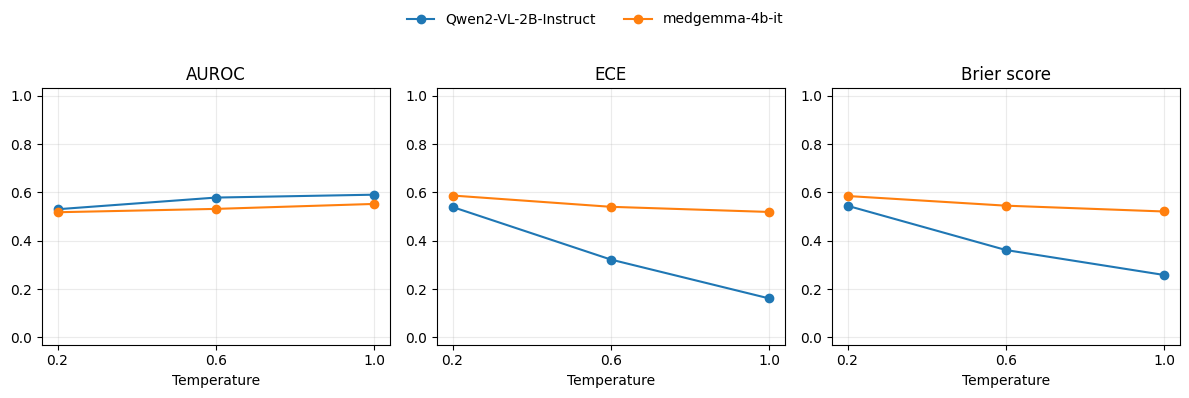

In [ ]:
#Q9
from pathlib import Path
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

folder = Path('/content/data/model_responses')
models = ['Qwen2-VL-2B-Instruct', 'medgemma-4b-it']
temperatures = [0.2, 0.6, 1.0]


def parse_answer(value):
    """Return A-E, or None for an invalid answer (e.g. [2], [AB])."""
    text = re.sub(r'\*\*|`', '', str(value)).strip()
    # [B], [ B ], [\nB\n], (A), B, B., B), B. lung, C: kidney
    for pattern in (r'[\[(]\s*([A-E])\s*[\])]', r'([A-E])[.)]?$', r'([A-E])[.:)](?:\s|$)'):
        match = re.match(pattern, text, re.I)
        if match:
            return match.group(1).upper()
    # "Answer: C", "final answer is (B)"
    matches = re.findall(r'\b(?:final\s+answer|correct\s+answer|answer)\s*'
                         r'(?:is\s*|[:=]\s*)[\[(]?\s*([A-E])\b', text, re.I)
    return matches[-1].upper() if matches else None


def count_options(value):
    options = ast.literal_eval(value) if isinstance(value, str) else value
    values = options.values() if isinstance(options, dict) else options
    return sum(pd.notna(v) and str(v).strip() != '' for v in values)


def evaluate(entropy, correct):
    """AUROC, ECE (10 bins, confidence 1 goes in the last bin) and Brier score."""
    auroc = roc_auc_score(1 - correct, entropy) if len(np.unique(correct)) == 2 else np.nan
    span = np.ptp(entropy)
    confidence = 1 - (entropy - entropy.min()) / span if span > 0 else np.ones_like(entropy, dtype=float)
    brier = np.mean((confidence - correct) ** 2)
    bins = np.minimum((confidence * 10).astype(int), 9)
    ece = sum((bins == b).mean() * abs(correct[bins == b].mean() - confidence[bins == b].mean())
              for b in range(10) if (bins == b).any())
    return auroc, ece, brier


# Load raw responses; unparseable answers become their own category 'INVALID'
files = {p.name.lower(): p for p in folder.glob('*.tsv')}
runs = {}
for model in models:
    for temp in temperatures:
        name = f'outputs_{model}-temp_{temp:.1f}.tsv'
        if name.lower() not in files:
            raise FileNotFoundError(f'Missing file: {folder / name}')
        df = pd.read_csv(files[name.lower()], sep='\t')
        df['parsed_response'] = df['response'].apply(parse_answer).fillna('INVALID')
        df['gold_label'] = df['gold_label'].apply(parse_answer)
        if df['gold_label'].isna().any():
            raise ValueError(f'{name}: some gold labels could not be parsed.')
        if 'num_options' not in df:
            df['num_options'] = df['options'].apply(count_options)
        invalid = (df['parsed_response'] == 'INVALID').mean()
        print(f'{name}: {invalid:.1%} invalid responses')
        runs[(model, temp)] = df

# Keep only questions with at least 10 samples in every run
common_ids = set.intersection(*[
    set(df['index'].value_counts().loc[lambda c: c >= 10].index) for df in runs.values()
])
if not common_ids:
    raise ValueError('No shared questions with at least 10 samples in every run.')

rows = []
for (model, temp), df in runs.items():
    selected = df[df['index'].isin(common_ids)].groupby('index').head(10)
    entropy, correct, _ = compute_semantic_entropy_uncertainty(selected)
    entropy, correct = np.asarray(entropy, float), np.asarray(correct, float)
    rows.append([model, temp, correct.mean(), entropy.mean(), *evaluate(entropy, correct)])

results = pd.DataFrame(rows, columns=['Model', 'Temperature', 'Accuracy',
                                      'Mean entropy', 'AUROC', 'ECE', 'Brier score'])
print(f'Shared questions: {len(common_ids)} | Samples per question: 10')
print(results.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ['AUROC', 'ECE', 'Brier score']):
    for model in models:
        g = results[results['Model'] == model]
        ax.plot(g['Temperature'], g[metric], marker='o', label=model)
    ax.set(title=metric, xlabel='Temperature', xticks=temperatures, ylim=(-0.03, 1.03))
    ax.grid(alpha=0.25)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

## Q10

In [ ]:

# Q10 - Extract label-prefix confidence and inspect tokenisation

file_paths = [
    "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
]

def get_label_confidence(logprobs):
    for i, (token, logprob) in enumerate(logprobs):

        # Prefix in one token, e.g. '[B'
        if re.fullmatch(r'\[[A-E]', token):
            return np.exp(logprob)

        # Prefix split into two tokens, e.g. '[' and 'B'
        if token.strip() == '[' and i + 1 < len(logprobs):
            next_token, next_logprob = logprobs[i + 1]

            if re.fullmatch(r'[A-E]', next_token.strip()):
                return np.exp(logprob + next_logprob)

    return np.nan


def get_tokenization_type(logprobs):
    for i, (token, logprob) in enumerate(logprobs):

        if re.fullmatch(r'\[[A-E]', token):
            return "One token"

        if token.strip() == '[' and i + 1 < len(logprobs):
            next_token = logprobs[i + 1][0]

            if re.fullmatch(r'[A-E]', next_token.strip()):
                return "Two tokens"

    return "Other / not detected"


# Exploratory analysis of Qwen2-VL-2B at temperature 1.0
df_raw = load_and_process_data(file_paths[0])

df_raw["parsed_logprobs"] = df_raw["logprobs"].apply(ast.literal_eval)

df_raw["label_confidence"] = df_raw["parsed_logprobs"].apply(
    get_label_confidence
)

df_raw["tokenization_type"] = df_raw["parsed_logprobs"].apply(
    get_tokenization_type
)

print("Tokenisation patterns:")
print(df_raw["tokenization_type"].value_counts())

print("\nResponses without extracted confidence:")
display(
    df_raw.loc[
        df_raw["label_confidence"].isna(),
        ["response", "logprobs"]
    ]
)


Tokenisation patterns:
tokenization_type
One token               2954
Two tokens                32
Other / not detected      14
Name: count, dtype: int64

Responses without extracted confidence:


,response,logprobs
124,[2],"[('[', -2.8539485931396484), ('2', -5.04449272..."
202,[AB],"[('[', -3.363659620285034), ('AB', -3.09508895..."
362,[AB],"[('[', -3.037727117538452), ('AB', -3.44784855..."
800,[BC],"[('[', -3.397300958633423), ('BC', -4.32741928..."
995,[BCD],"[('[', -3.4789950847625732), ('BC', -2.3868968..."
1126,E,"[('E', -3.413950204849243), ('<|im_end|>', -0...."
1824,[0],"[('[', -3.3052117824554443), ('0', -2.63000226..."
1915,[Ch],"[('[', -3.419769287109375), ('Ch', -3.62270855..."
1999,[CD],"[('[', -3.404648780822754), ('CD', -3.56488704..."
2271,E,"[('E', -3.2421393394470215), ('<|im_end|>', -0..."


In [ ]:
# Q10 - Majority-vote confidence and evaluation

from sklearn.metrics import roc_auc_score
from collections import Counter

def get_question_confidence(df):
    results = []

    for idx, group in df.groupby("index"):

        labels = group["parsed_response"].dropna()

        if labels.empty:
            continue

        majority_label = Counter(labels).most_common(1)[0][0]

        # Select responses supporting the majority answer
        matching = group[
            group["parsed_response"] == majority_label
        ]

        results.append({
            "index": idx,
            "majority_label": majority_label,
            "confidence": matching["label_confidence"].mean(),
            "correct": int(
                majority_label == str(group["gold_label"].iloc[0]).strip()
            )
        })

    return pd.DataFrame(results)


def evaluate_confidence(results_df):
    results_df = results_df.dropna(subset=["confidence"])

    confidence = results_df["confidence"].to_numpy()
    correctness = results_df["correct"].to_numpy()

    auroc = roc_auc_score(1 - correctness, 1 - confidence)
    brier = np.mean((confidence - correctness) ** 2)

    ece = 0
    bins = np.linspace(0, 1, 11)

    for i in range(10):
        if i == 9:
            mask = (confidence >= bins[i]) & (confidence <= bins[i + 1])
        else:
            mask = (confidence >= bins[i]) & (confidence < bins[i + 1])

        if mask.sum() > 0:
            ece += mask.mean() * abs(
                correctness[mask].mean() - confidence[mask].mean()
            )

    return {
        "AUROC": round(auroc, 3),
        "ECE": round(ece, 3),
        "Brier": round(brier, 3),
        "Questions": len(results_df)
    }


# Evaluate all four configurations
results_all = []

for file in file_paths:

    df = load_and_process_data(file)

    df["parsed_logprobs"] = df["logprobs"].apply(ast.literal_eval)

    df["label_confidence"] = df["parsed_logprobs"].apply(
        get_label_confidence
    )

    question_results = get_question_confidence(df)
    metrics = evaluate_confidence(question_results)

    metrics["Model"] = (
        "Qwen2.5-VL-32B" if "32B" in file else "Qwen2-VL-2B"
    )
    metrics["Temperature"] = file.split("temp_")[-1].replace(".tsv", "")

    results_all.append(metrics)

print("Evaluation results:")
display(pd.DataFrame(results_all))


# Two examples

print("\nHighest label-prefix confidence:")
display(
    df_raw.nlargest(1, "label_confidence")[
        ["index", "response", "gold_label", "label_confidence"]
    ]
)

print("\nLowest label-prefix confidence:")
display(
    df_raw.nsmallest(1, "label_confidence")[
        ["index", "response", "gold_label", "label_confidence"]
    ]
)

Evaluation results:


,AUROC,ECE,Brier,Questions,Model,Temperature
0,0.546,0.197,0.276,300,Qwen2-VL-2B,1.0
1,0.678,0.218,0.279,300,Qwen2.5-VL-32B,0.2
2,0.699,0.221,0.276,300,Qwen2.5-VL-32B,0.6
3,0.691,0.214,0.276,300,Qwen2.5-VL-32B,1.0



Highest label-prefix confidence:


,index,response,gold_label,label_confidence
600,454,[D] kidney boundary,E,0.966074



Lowest label-prefix confidence:


,index,response,gold_label,label_confidence
1115,1572,[A],D,0.000518


## Q11

In [ ]:
import torch
import torch.nn.functional as F

def compute_radial_dispersion_score(embeddings):
    # L2-normalise each embedding
    u = F.normalize(embeddings, p=2, dim=-1)

    # Calculate the mean embedding (centroid)
    u_bar = torch.mean(u, dim=0, keepdim=True)

    # Sum L1 distances from the centroid
    rds = torch.sum(torch.abs(u - u_bar))

    return rds.item()

In [ ]:
from sklearn.metrics import roc_auc_score, brier_score_loss
%pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer


embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
# Files for the four model configurations
file_paths = {
    "Qwen2-VL-2B (T=1.0)": "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv",
    "Qwen2.5-VL-32B (T=0.2)": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv",
    "Qwen2.5-VL-32B (T=0.6)": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
    "Qwen2.5-VL-32B (T=1.0)": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
}

# Expected Calibration Error (ECE)
def calculate_ece(correct, confidence, n_bins=10):
    ece = 0.0
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidence >= bin_edges[i]) & (confidence <= bin_edges[i + 1])
        else:
            mask = (confidence >= bin_edges[i]) & (confidence < bin_edges[i + 1])

        if mask.any():
            bin_accuracy = correct[mask].mean()
            bin_confidence = confidence[mask].mean()
            ece += mask.mean() * abs(bin_accuracy - bin_confidence)

    return ece


# Evaluate RDS for each model
all_results = []

for model_name, path in file_paths.items():

    # Use the provided data-loading function
    data = load_and_process_data(path)

    question_scores = []
    question_correct = []

    for question_id, group in data.groupby("index"):

        # Get the ten generated responses
        responses = group["response"].fillna("").astype(str).tolist()

        # Generate response embeddings
        embeddings = embedding_model.encode(
            responses,
            convert_to_tensor=True
        )

        # Calculate Radial Dispersion Score
        rds = compute_radial_dispersion_score(embeddings)

        # Majority-vote prediction using provided parsed responses
        answers = group["parsed_response"].tolist()
        prediction = Counter(answers).most_common(1)[0][0]
        gold = str(group["gold_label"].iloc[0]).strip()

        # Store uncertainty and correctness
        question_scores.append(rds)
        question_correct.append(int(prediction == gold))

    rds_scores = np.array(question_scores)
    correct = np.array(question_correct)

    # Convert RDS into confidence using the provided normalization approach
    u_min, u_max = rds_scores.min(), rds_scores.max()

    if u_max > u_min:
        normalized_rds = (rds_scores - u_min) / (u_max - u_min)
    else:
        normalized_rds = np.zeros_like(rds_scores)

    confidence = 1 - normalized_rds

    # Evaluation metrics
    auroc = roc_auc_score(1 - correct, rds_scores)
    ece = calculate_ece(correct, confidence)
    brier = brier_score_loss(correct, confidence)

    all_results.append({
        "Model": model_name,
        "Questions": len(correct),
        "AUROC": auroc,
        "ECE": ece,
        "Brier": brier
    })

# Display results
results_df = pd.DataFrame(all_results)
display(results_df.round(3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,Model,Questions,AUROC,ECE,Brier
0,Qwen2-VL-2B (T=1.0),300,0.542,0.168,0.259
1,Qwen2.5-VL-32B (T=0.2),300,0.509,0.167,0.297
2,Qwen2.5-VL-32B (T=0.6),300,0.581,0.123,0.262
3,Qwen2.5-VL-32B (T=1.0),300,0.642,0.132,0.252


In [ ]:
# Check if identical embeddings give RDS = 0

identical_embeddings = torch.ones(10, 384)
test_rds = compute_radial_dispersion_score(identical_embeddings)

print("RDS for identical embeddings:", test_rds)


RDS for identical embeddings: 1.430511474609375e-05


In [ ]:
#Q12
from sklearn.metrics import roc_auc_score

# One row per question: modality, semantic entropy
df = load_and_process_data("./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv")
unc, correct, _ = compute_semantic_entropy_uncertainty(df)   # same question order as groupby("index")
q = pd.DataFrame({"modality": df.groupby("index")["modality"].first().values, "unc": unc, "correct": correct})

# Normalise once over ALL questions, so confidences are comparable across modalities --> had to normalize otherwise calculating this was not possible
q["conf"] = 1 - (q["unc"] - q["unc"].min()) / (q["unc"].max() - q["unc"].min())

def metrics(g):
    both_classes = g["correct"].nunique() == 2
    return pd.Series({
        "Questions": len(g),
        "Accuracy": g["correct"].mean(),
        "AUROC": roc_auc_score(1 - g["correct"], g["unc"]) if both_classes else np.nan,
        "ECE": calculate_ece(g["correct"].values, g["conf"].values),
        "Brier": np.mean((g["conf"] - g["correct"]) ** 2),
    })

table = q.groupby("modality").apply(metrics)
table.loc["ALL"] = metrics(q)
display(table.sort_values("Accuracy", ascending=False).round(3))

/tmp/ipykernel_837/727121877.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table = q.groupby("modality").apply(metrics)


,Questions,Accuracy,AUROC,ECE,Brier
modality,,,,,
MRI,100.0,0.620,0.753,0.168,0.210
ALL,300.0,0.517,0.670,0.211,0.278
CT,100.0,0.480,0.635,0.289,0.312
X-ray,100.0,0.450,0.611,0.245,0.312


In [ ]:
#Q13
files = {
    "GPT-5-mini": "./data/model_responses/outputs_gpt5-mini_no-logprobs.tsv",
    "Qwen2.5-VL-32B (T=0.6)": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv",
}
dfs = {name: load_and_process_data(path) for name, path in files.items()}

# Checking that both models were evaluated on the same questions (with the same number of samples)
gpt, qwen = dfs["GPT-5-mini"], dfs["Qwen2.5-VL-32B (T=0.6)"]
common = set(gpt["index"]) & set(qwen["index"])
print("Common questions:", len(common))

rows = []
for name, d in dfs.items():
    d = d[d["index"].isin(common)]
    unc, correct, _ = compute_semantic_entropy_uncertainty(d)
    auroc, ece, brier = compute_calibration_metrics(unc, correct)
    rows.append({"Model": name, "Questions": len(correct), "Majority-vote accuracy": correct.mean(),
                 "AUROC": auroc, "ECE": ece, "Brier": brier})

display(pd.DataFrame(rows).round(3))

Common questions: 225


,Model,Questions,Majority-vote accuracy,AUROC,ECE,Brier
0,GPT-5-mini,225,0.693,0.638,0.226,0.238
1,Qwen2.5-VL-32B (T=0.6),225,0.560,0.657,0.252,0.298


In [ ]:

# Q15

files = {
    "Qwen2-VL-2B (T=1.0)": "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv",
    "Qwen2.5-VL-32B (T=1.0)": "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv"
}

results = []

for model_name, path in files.items():

    data = load_and_process_data(path)
    uncertainties, correct, num_options = compute_semantic_entropy_uncertainty(data)

    # Change the number of bins
    for n_bins in [5, 10, 20]:

        auroc, ece, brier = compute_calibration_metrics(
            uncertainties, correct, n_bins=n_bins
        )

        results.append({
            "Model": model_name,
            "Bins": n_bins,
            "ECE": ece
        })

q15_results_df = pd.DataFrame(results)

display(q15_results_df.round(3))


,Model,Bins,ECE
0,Qwen2-VL-2B (T=1.0),5,0.159
1,Qwen2-VL-2B (T=1.0),10,0.159
2,Qwen2-VL-2B (T=1.0),20,0.170
3,Qwen2.5-VL-32B (T=1.0),5,0.197
4,Qwen2.5-VL-32B (T=1.0),10,0.211
5,Qwen2.5-VL-32B (T=1.0),20,0.212


In [ ]:
# Q15 Reliability table
data = load_and_process_data(files["Qwen2.5-VL-32B (T=1.0)"])
uncertainties, correct, _ = compute_semantic_entropy_uncertainty(data)
u_min, u_max = uncertainties.min(), uncertainties.max()

if u_max > u_min:
    normalized_uncertainties = (uncertainties - u_min) / (u_max - u_min)
else:
    normalized_uncertainties = np.zeros_like(uncertainties)

confidence = 1 - normalized_uncertainties

# Reliability tables for 5 and 10 bins
for n_bins in [5, 10]:
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []

    for i in range(n_bins):
        mask = (normalized_uncertainties >= edges[i]) & (
            normalized_uncertainties < edges[i + 1]
        )

        if mask.any():
            rows.append({
                "Bin": i + 1,
                "Count": mask.sum(),
                "Mean confidence": confidence[mask].mean(),
                "Accuracy": correct[mask].mean()
            })

    print(f"\nReliability table: {n_bins} bins")
    display(pd.DataFrame(rows).round(3))



Reliability table: 5 bins


,Bin,Count,Mean confidence,Accuracy
0,1,118,1.000,0.703
1,2,57,0.741,0.456
2,3,62,0.542,0.419
3,4,55,0.344,0.345
4,5,7,0.116,0.143



Reliability table: 10 bins


,Bin,Count,Mean confidence,Accuracy
0,1,118,1.000,0.703
1,3,39,0.779,0.513
2,4,18,0.660,0.333
3,5,51,0.561,0.392
4,6,11,0.455,0.545
5,7,40,0.374,0.350
6,8,15,0.263,0.333
7,9,5,0.124,0.200
8,10,2,0.094,0.000


Q16

In [ ]:
# Q16
import os
import json
import ast
import torch
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm
from transformers import (
    AutoModelForImageTextToText,
    AutoProcessor,
)

model_id = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype="auto",
)

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype="auto",
    device_map="auto",
).eval()

print("Loaded model:", model_id)
print("Model device:", model.device)


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loaded model: Qwen/Qwen2-VL-2B-Instruct
Model device: cuda:0


In [ ]:
# Q16: Prepare data and define generation functions

import numpy as np

# Paths
DATASET_PATH = "/content/data/GMAI_mm_bench_dataset.tsv"
DATA_DIR = "/content/data/option_order_experiment"
IMAGES_DIR = "/content/data/images"

os.makedirs(DATA_DIR, exist_ok=True)

# Experiment settings
N_QUESTIONS = 50
SEED = 42
N_SAMPLES = 10

BATCH_SIZE = 4
MAX_NEW_TOKENS = 32
TEMPERATURE = 0.6
TOP_P = 0.9

OPTION_COLS = list("ABCDE")
CONDITIONS = ["original", "perm_1", "perm_2", "perm_3"]


# Prepare the fixed question subset and shuffled options
df = pd.read_csv(DATASET_PATH, sep="\t")

df["answer"] = (
    df["answer"]
    .astype(str)
    .str.strip()
    .str.upper()
)

valid = df["answer"].isin(OPTION_COLS)

for col in OPTION_COLS:
    valid &= (
        df[col].notna()
        & (df[col].astype(str).str.strip() != "")
    )

df = df.loc[valid].copy()

# Exclude questions with duplicate option texts
distinct_options = df[OPTION_COLS].apply(
    lambda row: len(set(row.astype(str).str.strip())) == 5,
    axis=1,
)

df = df.loc[distinct_options].copy()

if len(df) < N_QUESTIONS:
    raise ValueError(
        f"Only {len(df)} valid questions found; "
        f"{N_QUESTIONS} are required."
    )

# Select a reproducible subset
subset = df.sample(
    n=N_QUESTIONS,
    random_state=SEED,
).copy()

rng = np.random.default_rng(SEED)
prepared = {condition: [] for condition in CONDITIONS}

for _, row in subset.iterrows():

    original_options = {
        label: str(row[label])
        for label in OPTION_COLS
    }

    original_gold_text = original_options[row["answer"]]

    # Original condition
    prepared["original"].append({
        "index": row["index"],
        "question": row["question"],
        "image_path": row["image_path"],
        "options": json.dumps(
            original_options,
            ensure_ascii=False,
        ),
        "gold_label": row["answer"],
    })

    # Generate three distinct permutations
    seen_orders = {tuple(original_options.values())}

    for condition in ["perm_1", "perm_2", "perm_3"]:

        while True:
            shuffled_texts = list(original_options.values())
            rng.shuffle(shuffled_texts)
            order = tuple(shuffled_texts)

            if order not in seen_orders:
                seen_orders.add(order)
                break

        shuffled_options = dict(
            zip(OPTION_COLS, shuffled_texts)
        )

        # Track the new label of the correct answer text
        new_gold = next(
            label
            for label, text in shuffled_options.items()
            if text == original_gold_text
        )

        assert shuffled_options[new_gold] == original_gold_text

        prepared[condition].append({
            "index": row["index"],
            "question": row["question"],
            "image_path": row["image_path"],
            "options": json.dumps(
                shuffled_options,
                ensure_ascii=False,
            ),
            "gold_label": new_gold,
        })

# Save the four input files
for condition, records in prepared.items():

    output_path = os.path.join(
        DATA_DIR,
        f"{condition}.tsv",
    )

    pd.DataFrame(records).to_csv(
        output_path,
        sep="\t",
        index=False,
        encoding="utf-8",
    )

    print(f"Saved {output_path}: {len(records)} questions")


# Helper function: parse answer options
def parse_options(value):

    if isinstance(value, dict):
        return {str(k): str(v) for k, v in value.items()}

    if isinstance(value, str):
        try:
            parsed = json.loads(value)
        except json.JSONDecodeError:
            parsed = ast.literal_eval(value)

        if isinstance(parsed, dict):
            return {str(k): str(v) for k, v in parsed.items()}

        if isinstance(parsed, (list, tuple)):
            return dict(zip(OPTION_COLS, map(str, parsed)))

    if isinstance(value, (list, tuple)):
        return dict(zip(OPTION_COLS, map(str, value)))

    raise ValueError(f"Cannot process options: {value!r}")


# Helper function: build the prompt
def build_prompt(question, options):

    option_lines = "\n".join(
        f"{label}. {text}"
        for label, text in options.items()
    )

    return (
        "Answer the question based on the medical image.\n\n"
        f"Question: {question}\n\n"
        f"Answer options:\n{option_lines}\n\n"
        "Choose the best answer and respond with its letter only "
        "(for example, A or B)."
    )


# Generate responses for each question
def generate_responses(input_df, temperature, n_samples):

    required = [
        "index",
        "question",
        "image_path",
        "options",
        "gold_label",
    ]

    missing = [col for col in required if col not in input_df.columns]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    questions_df = input_df.drop_duplicates(
        subset="index"
    ).copy()

    records = []

    for _, row in questions_df.iterrows():
        for sample_number in range(n_samples):
            item = row.to_dict()
            item["sample_number"] = sample_number
            records.append(item)

    results = []

    for start in tqdm(
        range(0, len(records), BATCH_SIZE),
        desc="Generate answers",
    ):

        batch = records[start:start + BATCH_SIZE]
        prompts = []
        images = []
        batch_options = []

        for item in batch:

            options = parse_options(item["options"])
            batch_options.append(options)

            prompt = build_prompt(item["question"], options)

            messages = [{
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image"},
                ],
            }]

            chat_prompt = processor.apply_chat_template(
                messages,
                add_generation_prompt=True,
            )

            prompts.append(chat_prompt)

            filename = os.path.basename(str(item["image_path"]))
            image_path = os.path.join(IMAGES_DIR, filename)

            if not os.path.isfile(image_path):
                raise FileNotFoundError(
                    f"Image not found: {image_path}"
                )

            with Image.open(image_path) as img:
                images.append(img.convert("RGB").copy())

        if len(prompts) != len(images):
            raise ValueError(
                f"{len(prompts)} prompts but {len(images)} images."
            )

        inputs = processor(
            images=images,
            text=prompts,
            return_tensors="pt",
            padding=True,
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=(temperature > 0),
                **(
                    {"temperature": temperature, "top_p": TOP_P}
                    if temperature > 0
                    else {}
                ),
                return_dict_in_generate=True,
                output_scores=True,
                pad_token_id=processor.tokenizer.pad_token_id,
            )

        input_len = inputs["input_ids"].shape[1]

        for b_idx, item in enumerate(batch):

            generated_tokens = outputs.sequences[
                b_idx, input_len:
            ]

            generated_text = processor.decode(
                generated_tokens,
                skip_special_tokens=True,
            ).strip()

            token_logprobs = []

            for j, logits in enumerate(outputs.scores):

                if j >= len(generated_tokens):
                    break

                token_id = generated_tokens[j].item()

                logprob = torch.nn.functional.log_softmax(
                    logits[b_idx].float(),
                    dim=-1,
                )[token_id].item()

                token_str = processor.tokenizer.decode([token_id])

                token_logprobs.append((token_str, logprob))

            result = item.copy()
            result["options"] = json.dumps(
                batch_options[b_idx],
                ensure_ascii=False,
            )
            result["prompt"] = prompts[b_idx]
            result["response"] = generated_text
            result["logprobs"] = json.dumps(
                token_logprobs,
                ensure_ascii=False,
            )

            results.append(result)

    return pd.DataFrame(results)


print("Data preparation and generation functions are ready.")


Saved /content/data/option_order_experiment/original.tsv: 50 questions
Saved /content/data/option_order_experiment/perm_1.tsv: 50 questions
Saved /content/data/option_order_experiment/perm_2.tsv: 50 questions
Saved /content/data/option_order_experiment/perm_3.tsv: 50 questions
Data preparation and generation functions are ready.


In [ ]:
conditions = ["original", "perm_1", "perm_2", "perm_3"]

for condition in conditions:
    print(f"\n{'=' * 50}")
    print(f"Condition: {condition}")
    print(f"{'=' * 50}")

    input_path = os.path.join(DATA_DIR, f"{condition}.tsv")
    output_path = os.path.join(
        DATA_DIR, f"{condition}_responses.tsv"
    )

    if not os.path.isfile(input_path):
        raise FileNotFoundError(
            f"Dataset missing: {input_path}. "
            "Check whether the preparation step has been completed."
        )

    input_df = pd.read_csv(input_path, sep="\t")

    print("Unique questions in input:", input_df["index"].nunique())
    print("Rows in input:", len(input_df))

    output_df = generate_responses(
        input_df=input_df,
        temperature=TEMPERATURE,
        n_samples=N_SAMPLES,
    )

    output_df.to_csv(
        output_path,
        sep="\t",
        index=False,
        encoding="utf-8",
    )

    print("Saved:", output_path)
    print("Generated answers:", len(output_df))
    print("Unique questions:", output_df["index"].nunique())



Condition: original
Unique questions in input: 50
Rows in input: 50


Generate answers:   0%|          | 0/125 [00:00<?, ?it/s]

Saved: /content/data/option_order_experiment/original_responses.tsv
Generated answers: 500
Unique questions: 50

Condition: perm_1
Unique questions in input: 50
Rows in input: 50


Generate answers:   0%|          | 0/125 [00:00<?, ?it/s]

Saved: /content/data/option_order_experiment/perm_1_responses.tsv
Generated answers: 500
Unique questions: 50

Condition: perm_2
Unique questions in input: 50
Rows in input: 50


Generate answers:   0%|          | 0/125 [00:00<?, ?it/s]

Saved: /content/data/option_order_experiment/perm_2_responses.tsv
Generated answers: 500
Unique questions: 50

Condition: perm_3
Unique questions in input: 50
Rows in input: 50


Generate answers:   0%|          | 0/125 [00:00<?, ?it/s]

Saved: /content/data/option_order_experiment/perm_3_responses.tsv
Generated answers: 500
Unique questions: 50


In [ ]:
for condition in conditions:
    path = os.path.join(DATA_DIR, f"{condition}_responses.tsv")
    result = pd.read_csv(path, sep="\t")

    print(f"\n{condition}")
    print("Number of rows:", len(result))
    print("Number of questions:", result["index"].nunique())
    print("Missing responses:", result["response"].isna().sum())

    counts = result.groupby("index").size()
    print("Responses per question:", sorted(counts.unique()))

    print(
        result[
            ["index", "options", "gold_label", "response"]
        ].head(3).to_string(index=False)
    )


original
Number of rows: 500
Number of questions: 50
Missing responses: 0
Responses per question: [np.int64(10)]
 index                                                                                            options gold_label response
  1646 {"A": "cochlea", "B": "fourth ventricle", "C": "middle ear", "D": "temporal lobe", "E": "trachea"}          D        D
  1646 {"A": "cochlea", "B": "fourth ventricle", "C": "middle ear", "D": "temporal lobe", "E": "trachea"}          D        D
  1646 {"A": "cochlea", "B": "fourth ventricle", "C": "middle ear", "D": "temporal lobe", "E": "trachea"}          D        D

perm_1
Number of rows: 500
Number of questions: 50
Missing responses: 0
Responses per question: [np.int64(10)]
 index                                                                                            options gold_label response
  1646 {"A": "trachea", "B": "middle ear", "C": "temporal lobe", "D": "fourth ventricle", "E": "cochlea"}          C        C
  1646 {"A": "trac

In [ ]:
DATA_DIR = Path("data/option_order_experiment")
conditions = ["original", "perm_1", "perm_2", "perm_3"]

condition_data = {}
metric_rows = []

# Count answer options
def count_options(value):
    if isinstance(value, dict):
        return len(value)

    if isinstance(value, str):
        try:
            parsed = json.loads(value)
        except (json.JSONDecodeError, TypeError):
            parsed = ast.literal_eval(value)

        return len(parsed)

    return len(value)

# Load and prepare conditions
for condition in conditions:
    file_path = DATA_DIR / f"{condition}_responses.tsv"

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

    df_cond = pd.read_csv(file_path, sep="\t")

    required = ["index", "options", "gold_label", "response"]
    missing = [col for col in required if col not in df_cond.columns]

    if missing:
        raise ValueError(f"{condition} is missing columns: {missing}")

    # Semantic Entropy function
    df_cond["num_options"] = df_cond["options"].apply(count_options)

    # Parse generated answer
    df_cond["parsed_response"] = df_cond["response"].apply(parse_answer)

    # Standardize labels
    df_cond["gold_label"] = (
        df_cond["gold_label"].astype(str).str.strip().str.upper()
    )

    df_cond["parsed_response"] = df_cond["parsed_response"].apply(
        lambda x: str(x).strip().upper() if pd.notna(x) else None
    )

    # Check correctness of each individual generated response
    df_cond["is_correct"] = (
        df_cond["parsed_response"] == df_cond["gold_label"]
    ).fillna(False)

    condition_data[condition] = df_cond

    print(
        f"{condition}: {len(df_cond)} rows; "
        f"{df_cond['index'].nunique()} unique questions"
    )


for condition in conditions:
    df_cond = condition_data[condition]

    # Accuracy over individual generated responses
    accuracy = float(df_cond["is_correct"].mean())

    # Semantic entropy and question-level majority correctness
    entropy, correctness, num_options = (
        compute_semantic_entropy_uncertainty(df_cond)
    )

    # Evaluate
    evaluation = evaluate(entropy, correctness)

    # Expect evaluate() to return (AUROC, ECE, Brier score)
    # Verify this order against the function's implementation
    if isinstance(evaluation, dict):
        print(f"\n{condition}: evaluate() returned a dictionary:")
        print(evaluation)
        raise ValueError(
            "Check the keys returned by evaluate() and map them explicitly."
        )

    if len(evaluation) != 3:
        raise ValueError(
            f"Expected 3 values from evaluate(), got {len(evaluation)}."
        )

    auroc, ece, brier = map(float, evaluation)

    metric_rows.append({
        "Condition": condition,
        "Accuracy": accuracy,
        "AUROC": auroc,
        "ECE": ece,
        "Brier score": brier
    })


metrics_df = pd.DataFrame(metric_rows)

# Show results
print("\n Metrics by condition")
display(metrics_df.round(4))


baseline = metrics_df.loc[
    metrics_df["Condition"] == "original"
].iloc[0]

metric_names = ["Accuracy", "AUROC", "ECE", "Brier score"]

comparison_df = metrics_df[["Condition"] + metric_names].copy()

# Calculate the changes compared with the original ordering
for metric in metric_names:
    comparison_df[f"Delta {metric}"] = (
        comparison_df[metric] - baseline[metric]
    )

print("\n Changes relative to original ordering")
display(comparison_df.round(4))


original: 500 rows; 50 unique questions
perm_1: 500 rows; 50 unique questions
perm_2: 500 rows; 50 unique questions
perm_3: 500 rows; 50 unique questions

 Metrics by condition


,Condition,Accuracy,AUROC,ECE,Brier score
0,original,0.308,0.5571,0.6237,0.6203
1,perm_1,0.270,0.4911,0.6994,0.7000
2,perm_2,0.266,0.5021,0.6800,0.6936
3,perm_3,0.332,0.5009,0.6400,0.6400



 Changes relative to original ordering


,Condition,Accuracy,AUROC,ECE,Brier score,Delta Accuracy,Delta AUROC,Delta ECE,Delta Brier score
0,original,0.308,0.5571,0.6237,0.6203,0.000,0.0000,0.0000,0.0000
1,perm_1,0.270,0.4911,0.6994,0.7000,-0.038,-0.0661,0.0757,0.0797
2,perm_2,0.266,0.5021,0.6800,0.6936,-0.042,-0.0551,0.0563,0.0733
3,perm_3,0.332,0.5009,0.6400,0.6400,0.024,-0.0563,0.0163,0.0197


In [ ]:
import json
import ast
from collections import Counter

def options_to_dict(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return ast.literal_eval(value)
    return dict(zip("ABCDE", value))


def get_answer_content(row):
    label = parse_answer(row["response"])

    if label is None or pd.isna(label):
        return None

    options = options_to_dict(row["options"])
    return options.get(str(label).strip().upper())


# Find the most frequently selected answer for each question and condition
modal_rows = []

for condition, df_cond in condition_data.items():
    for question_id, group in df_cond.groupby("index"):
        contents = [
            get_answer_content(row)
            for _, row in group.iterrows()
        ]
        contents = [x for x in contents if x is not None]

        if not contents:
            continue

        counts = Counter(contents)
        content, count = counts.most_common(1)[0]

        modal_rows.append({
            "condition": condition,
            "index": question_id,
            "most_selected_content": content,
            "count": count,
            "valid_responses": len(contents),
            "selection_fraction": count / len(contents),
        })

modal_df = pd.DataFrame(modal_rows)

wide = modal_df.pivot(
    index="index",
    columns="condition",
    values="most_selected_content"
)

permutations = ["perm_1", "perm_2", "perm_3"]
changed_mask = wide[permutations].ne(wide["original"], axis=0).any(axis=1)

changed_questions = wide[changed_mask]

if changed_questions.empty:
    print(
        "No question was found for which the most frequently selected answer differed between the original order and a permutation."
    )
else:
    example_id = changed_questions.index[0]
    print("example-ID:", example_id)
    display(wide.loc[[example_id]])

    # Show the original question
    for condition in conditions:
        group = condition_data[condition]
        group = group[group["index"] == example_id]

        if group.empty:
            continue

        print(f"\n--- {condition} ---")
        print("Question:", group.iloc[0]["question"])
        print("Options:", options_to_dict(group.iloc[0]["options"]))
        print("Correct label:", group.iloc[0]["gold_label"])
        print("Generated answer:")

        display(group[["response", "gold_label", "is_correct"]])


example-ID: 46


condition,original,perm_1,perm_2,perm_3
index,,,,
46,pulmonary calcification,pulmonary calcification,diffuse pulmonary nodule,pulmonary consolidation



--- original ---
Question: Looking at the area highlighted by a box in this X-ray image, which of the following conditions is most consistent with the finding?
Options: {'A': 'pulmonary mass', 'B': 'pulmonary calcification', 'C': 'diffuse pulmonary nodule', 'D': 'pulmonary consolidation', 'E': 'pleural thickening'}
Correct label: E
Generated answer:


,response,gold_label,is_correct
280,B,E,False
281,B,E,False
282,B,E,False
283,B,E,False
284,B,E,False
285,B,E,False
286,B,E,False
287,B,E,False
288,B,E,False
289,B,E,False



--- perm_1 ---
Question: Looking at the area highlighted by a box in this X-ray image, which of the following conditions is most consistent with the finding?
Options: {'A': 'pulmonary mass', 'B': 'pulmonary calcification', 'C': 'pulmonary consolidation', 'D': 'pleural thickening', 'E': 'diffuse pulmonary nodule'}
Correct label: D
Generated answer:


,response,gold_label,is_correct
280,B,D,False
281,B,D,False
282,B,D,False
283,B,D,False
284,B,D,False
285,B,D,False
286,B,D,False
287,B,D,False
288,B,D,False
289,B,D,False



--- perm_2 ---
Question: Looking at the area highlighted by a box in this X-ray image, which of the following conditions is most consistent with the finding?
Options: {'A': 'pulmonary consolidation', 'B': 'pleural thickening', 'C': 'diffuse pulmonary nodule', 'D': 'pulmonary mass', 'E': 'pulmonary calcification'}
Correct label: B
Generated answer:


,response,gold_label,is_correct
280,C,B,False
281,B,B,True
282,C,B,False
283,C,B,False
284,C,B,False
285,B,B,True
286,B,B,True
287,C,B,False
288,B,B,True
289,B,B,True



--- perm_3 ---
Question: Looking at the area highlighted by a box in this X-ray image, which of the following conditions is most consistent with the finding?
Options: {'A': 'pleural thickening', 'B': 'pulmonary mass', 'C': 'pulmonary consolidation', 'D': 'diffuse pulmonary nodule', 'E': 'pulmonary calcification'}
Correct label: A
Generated answer:


,response,gold_label,is_correct
280,D,A,False
281,D,A,False
282,C,A,False
283,C,A,False
284,C,A,False
285,C,A,False
286,D,A,False
287,C,A,False
288,D,A,False
289,C,A,False


## Q17

In [ ]:
# Q17 setup: fixed subset (20 per modality) and an unrelated image from a different modality (based on cells 8, 13, 15 and 16)
random.seed(0)
subset = []
for mod in ["CT", "MRI", "X-ray"]:
    subset += random.sample([r for r in data_records if r["modality"] == mod], 20)
for r in subset:
    r["other_image"] = random.choice([x for x in data_records if x["modality"] != r["modality"]])["image_path"]

# Same as format_inputs (cell 15), but the image depends on the condition
def format_inputs_q17(item, mode):
    content = [{"type": "text", "text": item["prompt"]}]
    image = None
    if mode != "none":
        content.append({"type": "image"})
        path = item["image_path"] if mode == "original" else item["other_image"]
        image = Image.open(os.path.join(images_dir, path))
    return {**item, "messages": [{"role": "user", "content": content}], "image": image}

batch_size = 4
max_new_tokens = 32
temperature = 1.0
top_p = 0.9
sample_answers = 10

for mode in ["none", "unrelated"]:          # "original" is taken from the existing T=1.0 file
    data = [item for item in subset for _ in range(sample_answers)]
    results = []
    for i in tqdm(range(0, len(data), batch_size)):
        batch = [format_inputs_q17(item, mode) for item in data[i:i + batch_size]]
        prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
        images_batch = [item["image"] for item in batch]

        if mode == "none":
            inputs = processor(text=prompts_batch, return_tensors="pt", padding=True).to(model.device)
        else:
            inputs = processor(images=images_batch, text=prompts_batch, return_tensors="pt", padding=True).to(model.device)

        with torch.no_grad():
            outputs = model.generate(**inputs,
                max_new_tokens=max_new_tokens,
                do_sample=True,
                temperature=temperature,
                top_p=top_p,
                return_dict_in_generate=True,
                pad_token_id=processor.tokenizer.pad_token_id,
            )


        input_ids = inputs["input_ids"]
        for b_idx, item in enumerate(batch):
            input_len = input_ids[b_idx].shape[0]
            generated_tokens = outputs.sequences[b_idx, input_len:]
            results.append({
                "index": item["index"],
                "question": item["question"],
                "gold_label": item["answer"],
                "modality": item["modality"],
                "image_path": item["image_path"],
                "other_image": item["other_image"],
                "options": item["options"],
                "response": processor.decode(generated_tokens, skip_special_tokens=True),
            })

    os.makedirs("outputs", exist_ok=True)
    pd.DataFrame(results).to_csv(f"outputs/q17_{mode}.tsv", index=False, sep="\t", encoding="utf-8")

100%|██████████| 150/150 [12:09<00:00,  4.87s/it]


In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import os

def parse(r):   # accepts "[A] ...", "A", "A." etc. at the start of the response
    m = re.match(r"^\s*\[?\s*([A-E])\b", str(r))
    return m.group(1) if m else None

parts = {name: per_question(d) for name, d in conds.items()}

summary = pd.DataFrame({name: {"Questions": len(t),
                               "Sample accuracy": t["frac_correct"].mean(),
                               "Majority-vote accuracy": t["maj_correct"].mean(),
                               "Mean Semantic Entropy": t["SE"].mean()}
                        for name, t in parts.items()}).T
display(summary.round(3))

# Which letters does the model answer with in each condition?
for name, d in conds.items():
    print(name, d["response"].apply(parse).value_counts(dropna=False).to_dict())

wide = pd.concat([t[["maj", "SE"]].add_prefix(n + "_") for n, t in parts.items()], axis=1)
wide = wide.join(orig.groupby("index")[["gold_label", "modality", "question"]].first())
display(wide[wide["original_maj"] != wide["none_maj"]].round(2).head(10))

for idx in [941, 71, 1584]:
    r = orig[orig["index"] == idx].iloc[0]
    print(f"--- Q{idx} | {r['modality']} | gold: {r['gold_label']} ---")
    print(r["question"]); print(r["options"])
    print("Unrelated image used:", unrel[unrel["index"] == idx]["other_image"].iloc[0])

    # Use os.path.basename to get only the filename (e.g., '941.jpg')
    filename = os.path.basename(r["image_path"])
    img_path = os.path.join("data/images", filename)

    plt.figure(figsize=(3, 3)); plt.imshow(Image.open(img_path), cmap="gray"); plt.axis("off"); plt.show()

,Questions,Sample accuracy,Majority-vote accuracy,Mean Semantic Entropy
original,60.0,0.273,0.300,1.316
none,60.0,0.192,0.200,0.058
unrelated,60.0,0.242,0.233,0.076


original {'D': 169, 'C': 160, 'B': 150, 'A': 110, 'E': 9, None: 2}
none {'C': 179, 'B': 171, 'D': 125, 'A': 110, 'E': 15}
unrelated {'D': 215, 'C': 157, 'B': 138, 'A': 90}


,original_maj,original_SE,none_maj,none_SE,unrelated_maj,unrelated_SE,gold_label,modality,question
index,,,,,,,,,
71,D,0.88,C,-0.00,D,-0.00,D,X-ray,In the area enclosed by a box in this X-ray im...
398,B,1.30,C,-0.00,C,-0.00,D,X-ray,Which of the following options best matches th...
869,D,0.47,A,-0.00,D,-0.00,E,X-ray,Which of the following options best matches th...
941,C,1.16,A,-0.00,A,-0.00,C,X-ray,Observe the X-ray image. What is the most like...
1003,D,1.16,C,-0.00,C,0.72,A,X-ray,View the X-ray image provided. What is the lik...
1349,D,1.85,B,-0.00,B,0.97,A,CT,Which of the following options best matches th...
1362,D,1.69,B,-0.00,B,-0.00,C,MRI,This is a MRI image. Which of the following op...
1430,D,1.16,E,-0.00,D,-0.00,A,CT,This is a CT image. Which of the following opt...
1575,B,1.76,E,1.49,B,-0.00,D,CT,Considering the organ visible marked in the CT...


--- Q941 | X-ray | gold: C ---
Observe the X-ray image. What is the most likely abnormality shown in the highlight area?
{'A': 'retinal hemorrhages', 'B': 'esophageal cancer', 'C': 'rib fracture', 'D': 'pulmonary fibrosis'}
Unrelated image used: 2912.jpg


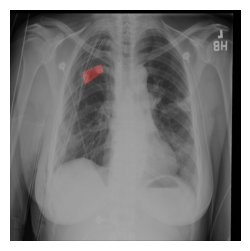

--- Q71 | X-ray | gold: D ---
In the area enclosed by a box in this X-ray image, what pathology is most likely present?
{'A': 'emphysema', 'B': 'pleural effusion', 'C': 'pulmonary nodule', 'D': 'pulmonary mass'}
Unrelated image used: 1652.jpg


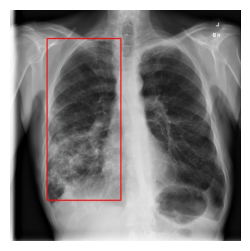

--- Q1584 | CT | gold: C ---
Which of the following options best matches the marked organ in the CT image?
{'A': 'gluteus medius', 'B': 'iliopsoas', 'C': 'gluteus maximus', 'D': 'gluteus minimus'}
Unrelated image used: 2912.jpg


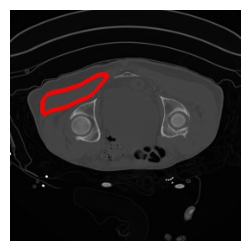

Q18

In [ ]:
import ast
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# Configuration
MODEL_NAME = "Qwen2.5-VL-32B (T=0.6)"
FILE_PATH = "./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv"

VALIDATION_FRACTION = 0.30
MAX_VALIDATION_REFERRAL_RATE = 0.20
RANDOM_SEED = 42
N_RANDOM_REPEATS = 1000

# Load the data
df = pd.read_csv(FILE_PATH, sep="\t")

print("Model:", MODEL_NAME)
print("Number of response rows:", len(df))
print("Available columns:", df.columns.tolist())

required_columns = [
    "question",
    "options",
    "gold_label",
    "response",
    "image_path"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")


# Parse predicted answers
def parse_response(response):
    """Extract the first bracketed multiple-choice answer."""

    if pd.isna(response):
        return None

    text = str(response).strip()

    match = re.search(r"\[([A-E])\]", text, flags=re.IGNORECASE)

    if match:
        return match.group(1).upper()

    # Fallback for responses such as "Answer: B"
    match = re.search(
        r"\b(?:answer|option|choice)\s*[:\-]?\s*([A-E])\b",
        text,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(1).upper()

    return None


df["parsed_response"] = df["response"].apply(parse_response)

df["gold_label_clean"] = (
    df["gold_label"].astype(str).str.strip().str.upper()
)

df["is_correct"] = (
    df["parsed_response"].notna()
    & (df["parsed_response"] == df["gold_label_clean"])
).astype(int)

parse_rate = df["parsed_response"].notna().mean()

print(f"\nResponse parsing success rate: {parse_rate:.3%}")
print(f"Correctness across individual samples: {df['is_correct'].mean():.3%}")

if parse_rate == 0:
    raise ValueError(
        "No answers could be parsed. Inspect the response format before continuing."
    )


# Calculate question-level uncertainty
def parse_options(options_value):
    """Parse the options column into a dictionary."""

    if isinstance(options_value, dict):
        return options_value

    try:
        parsed = ast.literal_eval(str(options_value))
        return parsed if isinstance(parsed, dict) else {}
    except (ValueError, SyntaxError):
        return {}


def normalize_answer_text(text):
    """Normalize option text for exact semantic matching."""

    return re.sub(r"\s+", " ", str(text).strip().lower())


def calculate_question_statistics(group):
    """
    Calculate one uncertainty score and one model prediction per question.

    Uncertainty is entropy over the normalized option texts selected
    across samples. Identical option texts form the same answer category.
    The final prediction is the most frequently selected answer letter.
    Ties are resolved by choosing the tied letter that appeared first.
    """

    valid = group[group["parsed_response"].notna()].copy()

    gold_label = group["gold_label_clean"].iloc[0]

    if valid.empty:
        return {
            "gold_label": gold_label,
            "predicted_label": None,
            "is_correct": 0,
            "uncertainty": np.inf,
            "n_samples": len(group),
            "n_parseable_samples": 0
        }

    options = parse_options(group["options"].iloc[0])

    # Map each predicted letter to its answer text.
    semantic_answers = []

    for letter in valid["parsed_response"]:
        option_text = options.get(letter, letter)
        semantic_answers.append(normalize_answer_text(option_text))

    # Shannon entropy of the answer-category distribution.
    counts = pd.Series(semantic_answers).value_counts().to_numpy()
    probabilities = counts / counts.sum()
    entropy = -np.sum(probabilities * np.log(probabilities))

    # Majority-vote answer. Ties are resolved by first appearance.
    letter_counts = valid["parsed_response"].value_counts()
    max_count = letter_counts.max()
    tied_letters = set(letter_counts[letter_counts == max_count].index)

    predicted_label = next(
        letter
        for letter in valid["parsed_response"]
        if letter in tied_letters
    )

    return {
        "gold_label": gold_label,
        "predicted_label": predicted_label,
        "is_correct": int(predicted_label == gold_label),
        "uncertainty": float(entropy),
        "n_samples": len(group),
        "n_parseable_samples": len(valid)
    }


# Group by question content and image to keep all samples
# belonging to the same question together.
GROUP_COLUMNS = ["question", "options", "gold_label", "image_path"]

question_records = []

for _, group in df.groupby(GROUP_COLUMNS, sort=False, dropna=False):
    stats = calculate_question_statistics(group)

    record = {column: group[column].iloc[0] for column in GROUP_COLUMNS}
    record.update(stats)
    question_records.append(record)

questions_df = pd.DataFrame(question_records).reset_index(drop=True)

print("\nNumber of unique questions:", len(questions_df))
print(
    "Questions with no parseable responses:",
    int((questions_df["n_parseable_samples"] == 0).sum())
)

if len(questions_df) < 2:
    raise ValueError("Not enough unique questions to create separate subsets.")


# Split into validation and test sets by question
all_question_ids = np.arange(len(questions_df))

validation_ids, test_ids = train_test_split(
    all_question_ids,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_SEED,
    shuffle=True
)

validation_df = questions_df.iloc[validation_ids].reset_index(drop=True)
test_df = questions_df.iloc[test_ids].reset_index(drop=True)

print("\nValidation questions:", len(validation_df))
print("Test questions:", len(test_df))


# Select the uncertainty threshold on validation only
def referral_metrics(data, threshold):
    """
    Refer questions whose uncertainty is strictly greater than threshold.
    Questions tied at the threshold are treated identically.
    """

    referred = data["uncertainty"].to_numpy() > threshold
    answered = ~referred

    n_questions = len(data)
    n_referred = int(referred.sum())
    n_answered = int(answered.sum())

    correct = data["is_correct"].to_numpy()

    coverage = n_answered / n_questions if n_questions else np.nan

    accuracy = (
        correct[answered].mean()
        if n_answered > 0
        else np.nan
    )

    incorrect_unflagged = int(
        ((correct == 0) & (~referred)).sum()
    )

    referral_rate = n_referred / n_questions if n_questions else np.nan

    return {
        "threshold": threshold,
        "n_questions": n_questions,
        "n_referred": n_referred,
        "n_answered": n_answered,
        "coverage": coverage,
        "accuracy_answered": accuracy,
        "incorrect_unflagged": incorrect_unflagged,
        "referral_rate": referral_rate
    }


# Test candidate thresholds using validation data only.
# Include infinity, which refers no questions.
candidate_thresholds = sorted(
    set(validation_df["uncertainty"].tolist())
)

if np.inf not in candidate_thresholds:
    candidate_thresholds.append(np.inf)

validation_results = []

for threshold in candidate_thresholds:
    metrics = referral_metrics(validation_df, threshold)

    if metrics["referral_rate"] <= MAX_VALIDATION_REFERRAL_RATE:
        validation_results.append(metrics)

if not validation_results:
    raise ValueError("No threshold satisfies the validation referral constraint.")

# Maximize accuracy among answered validation questions.
# Tie-break 1: prefer lower referral rate.
# Tie-break 2: prefer the higher threshold.
validation_results = sorted(
    validation_results,
    key=lambda result: (
        -1 if np.isnan(result["accuracy_answered"])
        else result["accuracy_answered"],
        -result["referral_rate"],
        result["threshold"]
    ),
    reverse=True
)

best_validation = validation_results[0]
selected_threshold = best_validation["threshold"]

print("\nSelected threshold:", selected_threshold)
print("Validation referral rate:", f"{best_validation['referral_rate']:.3%}")
print(
    "Validation accuracy among answered questions:",
    f"{best_validation['accuracy_answered']:.3%}"
)


# Apply the unchanged threshold to the test set
test_metrics = referral_metrics(test_df, selected_threshold)

print("\nTEST RESULTS")
print("------------")
print("Total questions:", test_metrics["n_questions"])
print("Referred questions:", test_metrics["n_referred"])
print("Answered questions:", test_metrics["n_answered"])
print("Coverage:", f"{test_metrics['coverage']:.3%}")
print(
    "Accuracy among answered questions:",
    f"{test_metrics['accuracy_answered']:.3%}"
)
print(
    "Incorrect answers left unflagged:",
    test_metrics["incorrect_unflagged"]
)
print("Observed referral proportion:", f"{test_metrics['referral_rate']:.3%}")


# Randomly refer exactly as many test questions as the
# uncertainty-based method referred.
n_test_questions = len(test_df)
n_random_referred = test_metrics["n_referred"]

test_correct = test_df["is_correct"].to_numpy()
rng = np.random.default_rng(RANDOM_SEED)

random_results = []

for repeat in range(N_RANDOM_REPEATS):
    random_referred_ids = rng.choice(
        n_test_questions,
        size=n_random_referred,
        replace=False
    )

    random_mask = np.zeros(n_test_questions, dtype=bool)
    random_mask[random_referred_ids] = True

    random_answered_mask = ~random_mask
    n_answered = int(random_answered_mask.sum())

    random_accuracy = (
        test_correct[random_answered_mask].mean()
        if n_answered > 0
        else np.nan
    )

    incorrect_unflagged = int(
        ((test_correct == 0) & random_answered_mask).sum()
    )

    random_results.append({
        "accuracy_answered": random_accuracy,
        "incorrect_unflagged": incorrect_unflagged,
        "referral_rate": n_random_referred / n_test_questions,
        "coverage": n_answered / n_test_questions
    })

random_df = pd.DataFrame(random_results)


# Summarize the random baseline
comparison_df = pd.DataFrame([
    {
        "Method": "Uncertainty-based referral",
        "Coverage": test_metrics["coverage"],
        "Accuracy among answered": test_metrics["accuracy_answered"],
        "Incorrect answers left unflagged": test_metrics["incorrect_unflagged"],
        "Referral proportion": test_metrics["referral_rate"]
    },
    {
        "Method": f"Random referral (mean of {N_RANDOM_REPEATS} runs)",
        "Coverage": random_df["coverage"].mean(),
        "Accuracy among answered": random_df["accuracy_answered"].mean(),
        "Incorrect answers left unflagged": random_df["incorrect_unflagged"].mean(),
        "Referral proportion": random_df["referral_rate"].mean()
    }
])

print("\nCOMPARISON")
print("----------")
print(comparison_df.to_string(
    index=False,
    formatters={
        "Coverage": "{:.3%}".format,
        "Accuracy among answered": "{:.3%}".format,
        "Referral proportion": "{:.3%}".format,
        "Incorrect answers left unflagged": "{:.2f}".format
    }
))

print("\nRANDOM BASELINE VARIABILITY")
print("--------------------------")

for metric in [
    "accuracy_answered",
    "incorrect_unflagged",
    "coverage",
    "referral_rate"
]:
    print(
        f"{metric}: "
        f"mean={random_df[metric].mean():.4f}, "
        f"std={random_df[metric].std():.4f}, "
        f"min={random_df[metric].min():.4f}, "
        f"max={random_df[metric].max():.4f}"
    )


# Check the validation referral constraint on test data
print("\nREFERRAL CONSTRAINT CHECK")
print("-------------------------")
print(
    "Validation referral limit:",
    f"{MAX_VALIDATION_REFERRAL_RATE:.1%}"
)
print(
    "Validation referral proportion:",
    f"{best_validation['referral_rate']:.3%}"
)
print(
    "Test referral proportion:",
    f"{test_metrics['referral_rate']:.3%}"
)
print(
    "Did the test set also meet the 20% limit?",
    "Yes" if test_metrics["referral_rate"] <= MAX_VALIDATION_REFERRAL_RATE
    else "No"
)



Model: Qwen2.5-VL-32B (T=0.6)
Number of response rows: 3000
Available columns: ['index', 'shuffle_index', 'question', 'options', 'gold_label', 'prompt', 'image_path', 'response', 'logprobs', 'input_logprobs', 'full_distribution_file', 'category', 'clinical VQA task', 'department', 'perceptual granularity', 'modality']

Response parsing success rate: 99.733%
Correctness across individual samples: 49.733%

Number of unique questions: 300
Questions with no parseable responses: 0

Validation questions: 210
Test questions: 90

Selected threshold: 0.6108643020548935
Validation referral rate: 16.190%
Validation accuracy among answered questions: 53.977%

TEST RESULTS
------------
Total questions: 90
Referred questions: 16
Answered questions: 74
Coverage: 82.222%
Accuracy among answered questions: 58.108%
Incorrect answers left unflagged: 31
Observed referral proportion: 17.778%

COMPARISON
----------
                             Method Coverage Accuracy among answered Incorrect answers left u